## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Andres Felipe Marin Velez" 
carnet = 1000112123


## 1) Descripción del problema 


En un negocio se necesota optimizar la busqueda de productos por codigo de los productos, para optimizar este proseso se tiene que utilizar las tablas hash y se debe poder  guardar el codigo, el nombre del producto, el precio y cantidad disponible.

## 2) Requerimientos 

Lista requerimientos **funcionales** y **no funcionales**.



*Funcionales*
RF01: El sistema deberá solicitar al usuario el tamaño de la Tabla Hash (m) para su creación.

RF02: El sistema deberá inicializar la Tabla Hash con todas sus posiciones vacías.

RF03: El sistema deberá solicitar al usuario la cantidad de productos que desea registrar.

RF04: El sistema deberá permitir ingresar los datos de cada producto: código, nombre, precio y cantidad disponible.

RF05: El sistema deberá calcular la posición de almacenamiento de cada producto mediante la función hash: h(código) = código % m.

*No funcionales*
RNF-01: El código será desarrollado en python.

RNF-02: La tabla hash se implementará de manera manual, y sin diccionarios.

RNF-03: El código usará la función establecida del hash.

RNF-04: El código manejará las colisiones por encadenamiento.

RNF-05: El código será sencillo e intuitivo para el usuario.


## 3) Historias de usuario 
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.


1. Como administrador quiero poder ingresar el tamaño de la tabla hash

    criterios de aceptacion:

    El sistema solicita el valor de m.

    La tabla se crea con ese tamaño.

    Todas las posiciones quedan vacías al inicio


2. Como usuario me gustaria ingresar la cantidad de productos e ingrezar los productos esa cantidad de veces

    criterios de aceptacion:

    El sistema pregunta la cantidad de prodictos.

    El sistema permite ingresar los datos esa cantidad de veces.


3.  como ususrio me gustaria que el sistema calcule automaticamente donde guardar cada producto usando la funcion h(codigo) = coigo % m.

    criterios de aceptacion:

    El sistema aplica la funcion de hash

    El producto se guarda en la pocicion calculada



## 4) Diagramas de flujo
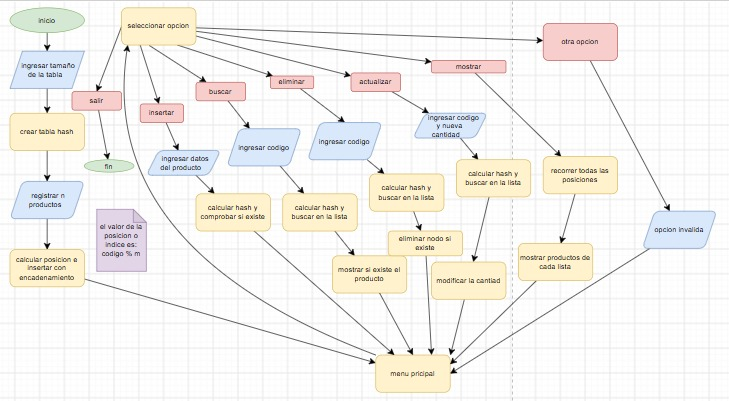

### 5) Análisis de complejidad

 La función hash tiene complejidad O(1), ya que calcula directamente la posición del producto. La inserción también es O(1) amortizado, mientras que la búsqueda, eliminación y actualización tienen un mejor caso O(1) y un peor caso O(n), cuando todos los productos se encuentran en una misma posición debido a las colisiones. Mostrar la tabla completa tiene complejidad O(m+n), porque recorre las casillas y sus productos.

- `m`: tamaño de la tabla hash.
- `n`: cantidad total de productos.
- `L`: cantidad de productos en la casilla consultada (`0 ≤ L ≤ n`).



#### Gráfica 1. Mejor y peor caso

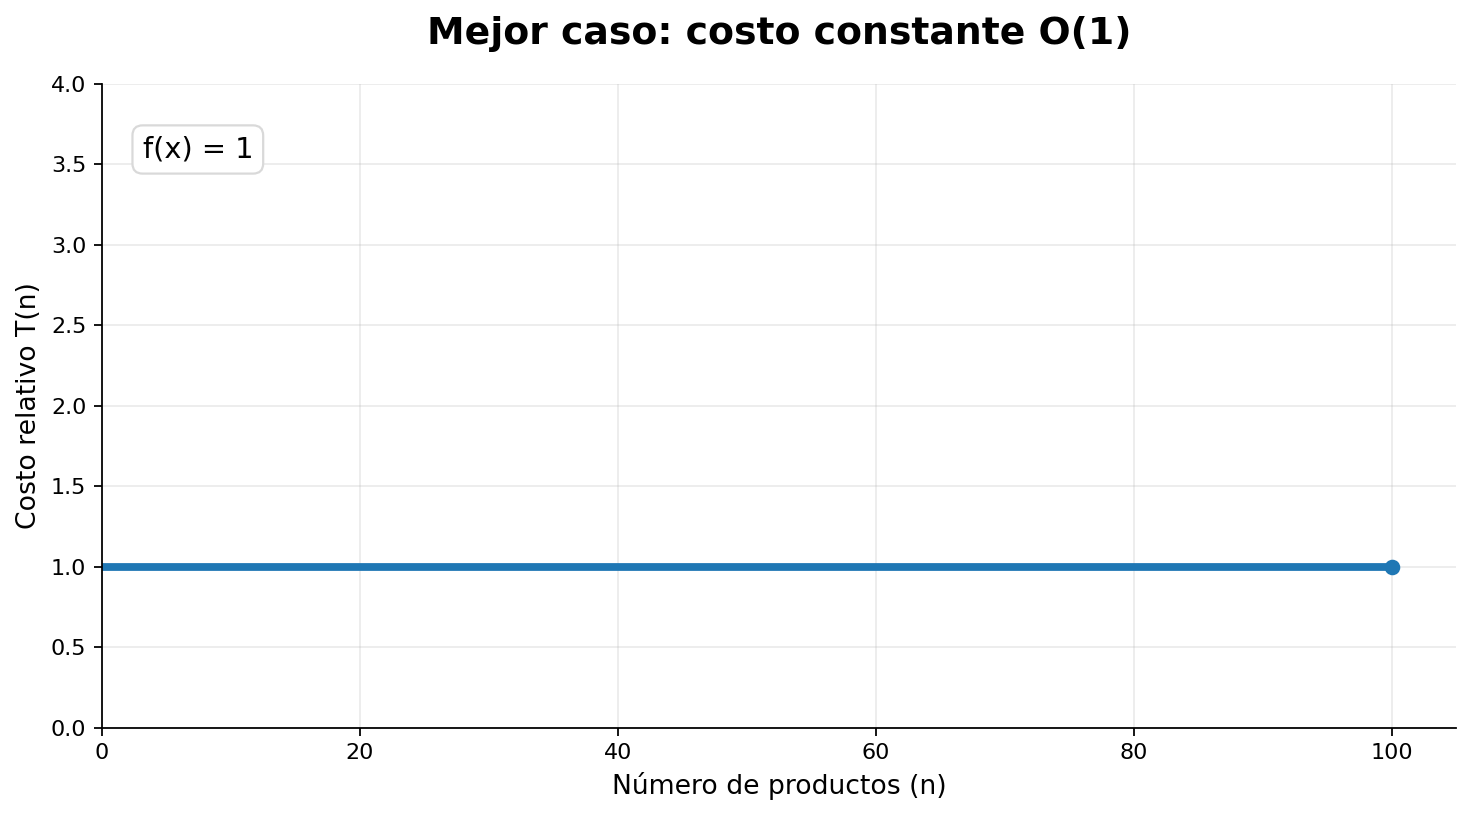


Peor Caso

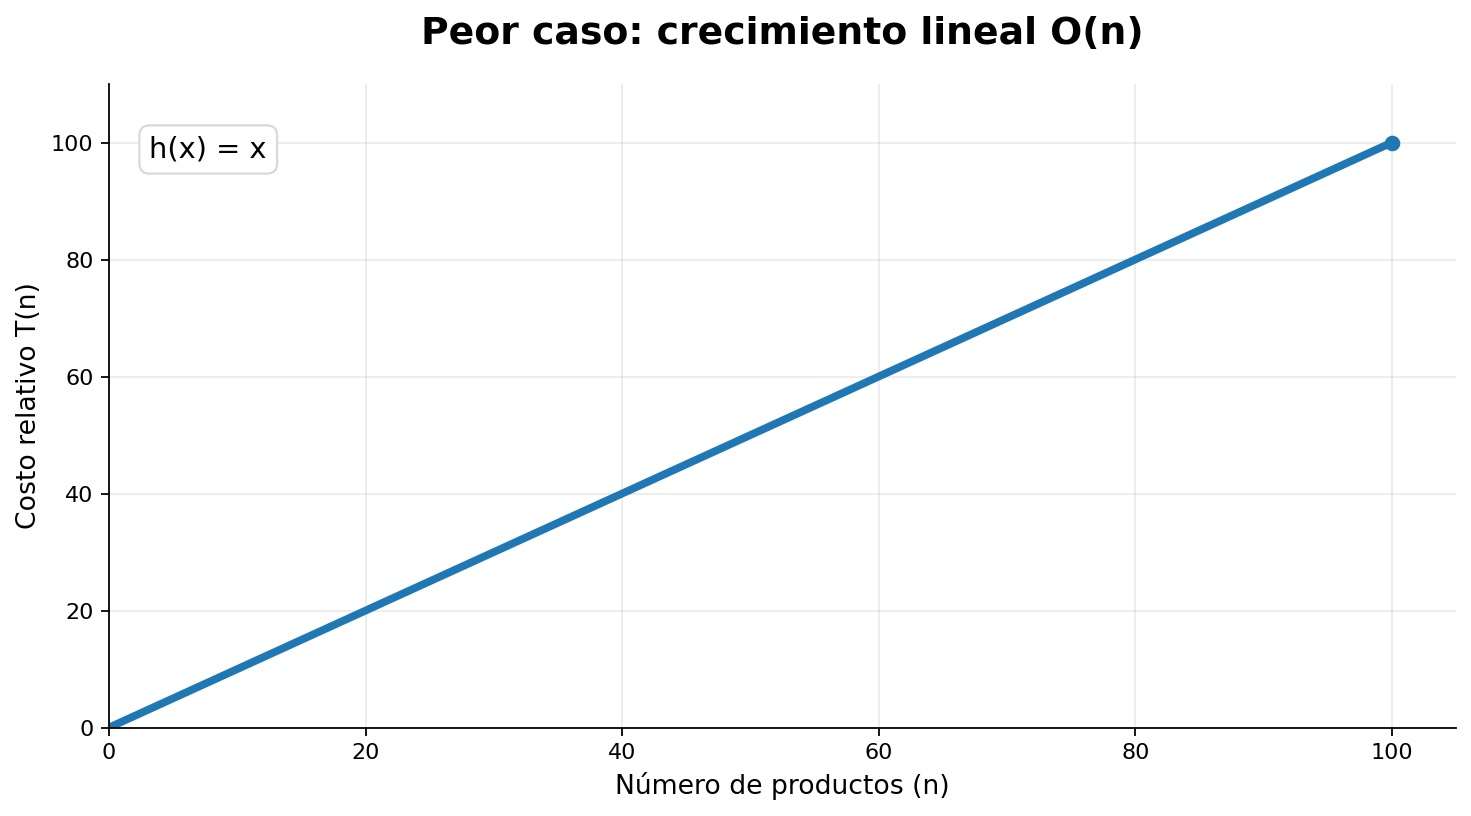








## 6) Código funcional 
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [2]:

def ingresar_p(tabla):
    
    n_productos = int(input("Cuantos productos va a ingresar?: "))

    for i in range (n_productos):
        productos = []
        codigo = int(input("Ingrese el codigo del producto: ")) 
        nombre = str(input("Ingrese el nombre del producto: ")) 
        precio = float(input("Ingrese el precio del producto: "))
        cantidad_d = int(input("Ingrese la cantidad disponible del producto: "))
        posi = funcion_hash(codigo, len(tabla))
        productos.append(codigo)
        productos.append(nombre)
        productos.append(precio)
        productos.append(cantidad_d)
        tabla[posi].append(productos)  

    return tabla


def funcion_hash(codigo, m):
    if codigo < 0:
        print("El codigo es invalido")
    posicion = codigo % m
    return posicion

def buscar_productos(tabla, codigo_b):
    posicion = funcion_hash(codigo_b, len(tabla))
    lista_p = tabla[posicion]

    if len(lista_p) == 0:
        print("No hay productos en esta pocicion")
        return None
    for producto in lista_p:
        if producto[0] == codigo_b:
            print("Producto encontrado: ", producto)
            return producto

def eliminar_producto(tabla, codigo_e):
    posicion = funcion_hash(codigo_e, len(tabla))
    lista_p = tabla[posicion]

    if len(lista_p) == 0:
        print("No hay productos en esta pocicion")
        return None
    
    for i, producto in enumerate(lista_p):
        if producto[0] == codigo_e:
            del tabla[posicion][i]
            print("Producto eliminado")
            return tabla

def actualizar_codigo(tabla, codigo_a):
    posicion = funcion_hash(codigo_a, len(tabla))
    lista_p = tabla[posicion]

    if len(lista_p) == 0:
        print("No hay productos en esta pocicion")
        return None
    
    for i, producto in enumerate(lista_p):
        if producto[0] == codigo_a:
            tabla[posicion][i]

            print('''Que vas a actualizar?:
            a. Nombre
            b. Precio
            c. Cantidad disponible
            ''')

            a = input("Ingresa la letra del elemento que vas a actualizar: ")
            if a == "a":
                tabla[posicion][i][1] = input("Ingresa el nuevo nombre del producto: ")
            elif a == "b":
                tabla[posicion][i][2] = float(input("Ingresa el nuevo precio del producto: "))
            elif a == "c":
                tabla[posicion][i][3] = int(input("Ingresa la nueva cantidad del producto: "))
            else:
                print("Esa opcion no esta disponible")

            return tabla

def main():
    try:
        num_casillas = int(input("¿Cuántas casillas va a tener la tabla hash?: "))
        if num_casillas <= 0:
            print("El número de casillas debe ser mayor a 0.")
            return
    except ValueError:
        print("Error: Debes ingresar un número entero.")
        return

    tabla_hash = [[] for _ in range(num_casillas)]
    print(f"\n Tabla hash creada con {num_casillas} casillas.\n")

    while True:
        print("\n" + "="*40)
        print("        MENÚ PRINCIPAL - TABLA HASH")
        print("="*40)
        print("1. Ingresar un producto")
        print("2. Buscar un producto por código")
        print("3. Eliminar un producto")
        print("4. Actualizar un producto")
        print("5. Ver la tabla hash completa")
        print("6. Salir")
        print("="*40)

        opcion = input("Selecciona una opción (1-6): ").strip()

        if opcion == "1":
            ingresar_p(tabla_hash)
        
        elif opcion == "2":
            try:
                codigo = int(input("¿Qué código necesitas buscar?: "))
                buscar_productos(tabla_hash, codigo)
            except ValueError:
                print("Error: El código debe ser un número entero.")
        
        elif opcion == "3":
            try:
                codigo = int(input("¿Qué código vas a eliminar?: "))
                eliminar_producto(tabla_hash, codigo)
            except ValueError:
                print("Error: El código debe ser un número entero.")
        
        elif opcion == "4":
            try:
                codigo = int(input("¿Qué código vas a actualizar?: "))
                actualizar_codigo(tabla_hash, codigo)
            except ValueError:
                print("Error: El código debe ser un número entero.")
        
        elif opcion == "5":
            print("\n ESTADO ACTUAL DE LA TABLA HASH:")

            tabla_vacia = True
            for i, casilla in enumerate(tabla_hash):
                if len(casilla) > 0:
                    print(f"  Casilla {i}: {casilla}")
                    tabla_vacia = False
            if tabla_vacia:
                print("  (La tabla está vacía)")
        
        elif opcion == "6":
            print("\n Saliendo del programa. ¡Hasta luego!")
            break
        
        else:
            print("\n Opción no válida. Por favor, elige un número del 1 al 6.")

        input("\nPresiona Enter para volver al menú...")

main()

Error: Debes ingresar un número entero.


## 7) Tests aplicados **[15 pts]**

Las siguientes pruebas utilizan **las funciones originales** del apartado 6, sin modificarlas. Para ejecutarlas, primero ejecuta el código funcional y **sal del menú con la opción 6**; luego ejecuta la celda de pruebas.

Se comprueban la creación de la tabla, la función hash, inserción, colisiones, búsqueda exitosa y fallida, eliminación y actualización. También se incluyen comprobaciones de requisitos que el código actual **todavía no cumple**: los resultados de esas pruebas se identifican como **PENDIENTE**, en lugar de afirmar que fueron aprobadas.


In [3]:
# PRUEBAS DEL INVENTARIO CON TABLA HASH
# Se usan las funciones originales del apartado 6, sin reescribirlas.
from unittest.mock import patch
from contextlib import redirect_stdout
from io import StringIO


def ingreso_simulado(tabla, datos):
    """Ejecuta ingresar_p sin tener que escribir a mano los datos."""
    respuestas = [str(len(datos))]
    for codigo, nombre, precio, cantidad in datos:
        respuestas.extend([str(codigo), nombre, str(precio), str(cantidad)])
    with patch("builtins.input", side_effect=respuestas), redirect_stdout(StringIO()):
        return ingresar_p(tabla)


def crear_ejemplo():
    """Prepara la tabla de 7 casillas y provoca una triple colisión."""
    tabla = [[] for _ in range(7)]
    datos = [
        (101, "Arroz", 4500, 20),
        (108, "Huevos", 16000, 12),
        (115, "Azúcar", 4200, 8),
        (302, "Galletas", 2500, 10),
        (312, "Café", 12000, 15),
        (209, "Leche", 3800, 20),
    ]
    ingreso_simulado(tabla, datos)
    return tabla


def llamada_silenciosa(funcion, *args):
    """Evita imprimir los mensajes de funciones durante un test."""
    with redirect_stdout(StringIO()):
        return funcion(*args)


resultados = []


def verificar(nombre, prueba):
    try:
        prueba()
        print(f"APROBADA: {nombre}")
        resultados.append((nombre, True))
    except AssertionError as error:
        print(f"PENDIENTE: {nombre} - {error}")
        resultados.append((nombre, False))
    except Exception as error:
        print(f"ERROR: {nombre} - {type(error).__name__}: {error}")
        resultados.append((nombre, False))


def prueba_creacion():
    tabla = [[] for _ in range(7)]
    assert len(tabla) == 7 and all(len(casilla) == 0 for casilla in tabla), "La tabla inicial no está vacía."


def prueba_hash():
    assert funcion_hash(101, 7) == 3, "101 % 7 debe ser 3."
    assert funcion_hash(108, 7) == 3, "108 % 7 debe ser 3."


def prueba_insercion():
    tabla = crear_ejemplo()
    assert sum(len(casilla) for casilla in tabla) == 6, "No se insertaron los seis productos."
    assert tabla[3][0] == [101, "Arroz", 4500.0, 20], "Los datos del arroz son incorrectos."


def prueba_colisiones():
    tabla = crear_ejemplo()
    codigos = [producto[0] for producto in tabla[3]]
    assert codigos == [101, 108, 115], "La casilla 3 no contiene las tres colisiones esperadas."


def prueba_busqueda_encontrada():
    tabla = crear_ejemplo()
    producto = llamada_silenciosa(buscar_productos, tabla, 108)
    assert producto == [108, "Huevos", 16000.0, 12], "No se encontró el producto 108."


def prueba_busqueda_inexistente():
    tabla = crear_ejemplo()
    assert llamada_silenciosa(buscar_productos, tabla, 999) is None, "La búsqueda inexistente debe devolver None."


def prueba_eliminacion():
    tabla = crear_ejemplo()
    llamada_silenciosa(eliminar_producto, tabla, 108)
    assert llamada_silenciosa(buscar_productos, tabla, 108) is None, "No se eliminó el código 108."
    assert [p[0] for p in tabla[3]] == [101, 115], "Se eliminaron elementos incorrectos de la cadena."


def prueba_actualizacion():
    tabla = crear_ejemplo()
    with patch("builtins.input", side_effect=["c", "35"]), redirect_stdout(StringIO()):
        actualizar_codigo(tabla, 101)
    producto = llamada_silenciosa(buscar_productos, tabla, 101)
    assert producto[3] == 35, "La cantidad del arroz no cambió a 35."


def prueba_tamano_invalido():
    salida = StringIO()
    with patch("builtins.input", side_effect=["0"]), redirect_stdout(salida):
        main()
    assert "mayor a 0" in salida.getvalue(), "No se rechazó el tamaño cero."


def prueba_sin_duplicados():
    tabla = crear_ejemplo()
    ingreso_simulado(tabla, [(101, "Arroz duplicado", 5000, 1)])
    repeticiones = sum(p[0] == 101 for casilla in tabla for p in casilla)
    assert repeticiones == 1, "El código 101 se guarda dos veces; se debe impedir."


def prueba_mensaje_ausente_en_colision():
    tabla = crear_ejemplo()
    salida = StringIO()
    with redirect_stdout(salida):
        resultado = buscar_productos(tabla, 122)  # 122 % 7 = 3; el código no existe
    assert resultado is None, "El código 122 no debería existir."
    assert "no" in salida.getvalue().lower(), "No informa que el producto 122 no está registrado."


def prueba_ver_todas_las_casillas():
    salida = StringIO()
    with patch("builtins.input", side_effect=["7", "5", "", "6"]), redirect_stdout(salida):
        main()
    texto = salida.getvalue()
    assert "Casilla 0:" in texto and "Casilla 6:" in texto, "Debe mostrar también las casillas vacías."


def prueba_codigo_negativo():
    tabla = [[] for _ in range(7)]
    ingreso_simulado(tabla, [(-1, "Inválido", 200, 1)])
    assert not any(p[0] < 0 for casilla in tabla for p in casilla), "Acepta códigos negativos."


print("=" * 60)
print("PRUEBAS DE LA TABLA HASH - IMPLEMENTACIÓN ORIGINAL")
print("=" * 60)
verificar("1. Creación de la tabla", prueba_creacion)
verificar("2. Función hash (módulo)", prueba_hash)
verificar("3. Inserción de productos", prueba_insercion)
verificar("4. Colisiones por encadenamiento", prueba_colisiones)
verificar("5. Búsqueda exitosa", prueba_busqueda_encontrada)
verificar("6. Búsqueda de código inexistente", prueba_busqueda_inexistente)
verificar("7. Eliminación sin afectar la cadena", prueba_eliminacion)
verificar("8. Actualización de cantidad", prueba_actualizacion)
verificar("9. Validación del tamaño de tabla", prueba_tamano_invalido)



print("\nEVIDENCIA: TABLA DESPUÉS DE LAS INSERCIONES (m = 7)")
for indice, casilla in enumerate(crear_ejemplo()):
    descripcion = " -> ".join(f"{p[0]} - {p[1]}" for p in casilla) if casilla else "Vacío"
    print(f"{indice} -> {descripcion}")


PRUEBAS DE LA TABLA HASH - IMPLEMENTACIÓN ORIGINAL
APROBADA: 1. Creación de la tabla
APROBADA: 2. Función hash (módulo)
APROBADA: 3. Inserción de productos
APROBADA: 4. Colisiones por encadenamiento
APROBADA: 5. Búsqueda exitosa
APROBADA: 6. Búsqueda de código inexistente
APROBADA: 7. Eliminación sin afectar la cadena
APROBADA: 8. Actualización de cantidad
APROBADA: 9. Validación del tamaño de tabla

EVIDENCIA: TABLA DESPUÉS DE LAS INSERCIONES (m = 7)
0 -> Vacío
1 -> 302 - Galletas
2 -> Vacío
3 -> 101 - Arroz -> 108 - Huevos -> 115 - Azúcar
4 -> 312 - Café
5 -> Vacío
6 -> 209 - Leche
